# Notebook 02: Building, Training & Comparing Neural Language Models
## DSL 504 — NLP Group Assignment 2 | Question 4: The Plot-Twist Generator

This notebook covers **Part 2 (40 Marks)** of the assignment:
1. **Model A: Vanilla RNN Language Model** (`Embedding -> Vanilla RNN -> Linear -> Vocabulary Logits`).
2. **Model B: LSTM Language Model** (`Embedding -> LSTM -> Linear -> Vocabulary Logits`).
3. **Matched Experimental Conditions**: Identical vocabulary ($|V|=8,801$), embedding dimension ($d_e=256$), hidden dimension ($d_h=512$), number of layers ($L=2$), and optimizer settings.
4. **Parameter Breakdown & Theoretical Differences**: Quantifying the $4\times$ recurrent parameter multiplier in LSTM and its mathematical advantages.
5. **Quantitative Comparison**: Loss curves, training durations, and held-out test set perplexity.

In [1]:
import os
import sys
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Ensure project root is accessible
project_root = os.path.abspath("..")
if project_root not in sys.path:
    sys.path.append(project_root)

from src.utils import set_seed, CONFIG
from src.models import VanillaRNNLanguageModel, LSTMLanguageModel, count_parameters
from src.data_prep import Vocabulary

set_seed(CONFIG.get("seed", 42))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Computation Device:", device)

C:\Tech-notes-prac-etc\NLP\Group Assignment 2\Question_4\plot_twist_generator\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Computation Device: cpu


### 1. Mathematical Architecture Formulation

#### Model A: Vanilla Elman RNN
Given embedding $e_t \in \mathbb{R}^{d_e}$ and hidden state $h_{t-1} \in \mathbb{R}^{d_h}$:
$$
h_t = \tanh(W_{ih} e_t + b_{ih} + W_{hh} h_{t-1} + b_{hh})
$$
$$
\hat{y}_t = W_{\text{out}} h_t + b_{\text{out}} \in \mathbb{R}^{|V|}
$$
*Limitation*: The recurrent Jacobian product $\prod_{k=1}^t \frac{\partial h_k}{\partial h_{k-1}}$ causes exponential gradient decay (vanishing gradients), making it difficult for the model to remember story characters or setup across long horizons.

---

#### Model B: Long Short-Term Memory (LSTM)
LSTMs introduce gated regulation and an additive cell state highway $c_t$:
$$\begin{aligned}
i_t &= \sigma(W_{ii} e_t + b_{ii} + W_{hi} h_{t-1} + b_{hi}) \quad &\text{(Input Gate: what new information to store)} \\
f_t &= \sigma(W_{if} e_t + b_{if} + W_{hf} h_{t-1} + b_{hf}) \quad &\text{(Forget Gate: what past context to discard)} \\
g_t &= \tanh(W_{ig} e_t + b_{ig} + W_{hg} h_{t-1} + b_{hg}) \quad &\text{(Candidate Cell Update)} \\
o_t &= \sigma(W_{io} e_t + b_{io} + W_{ho} h_{t-1} + b_{ho}) \quad &\text{(Output Gate: what to expose to hidden state)} \\
c_t &= f_t \odot c_{t-1} + i_t \odot g_t \quad &\mathbf{(Additive\ Gradient\ Highway)} \\
h_t &= o_t \odot \tanh(c_t)
\end{aligned}$$
*Advantage*: When $f_t \approx 1$, the gradient flows back across time steps with minimal attenuation $\left(\frac{\partial c_t}{\partial c_{t-1}} = f_t\right)$, allowing the LSTM to preserve narrative consistency.

In [2]:
vocab = Vocabulary.load(os.path.join(project_root, "checkpoints", "vocab.json"))
vocab_size = len(vocab)

rnn_model = VanillaRNNLanguageModel(vocab_size=vocab_size, embed_dim=256, hidden_dim=512, num_layers=2)
lstm_model = LSTMLanguageModel(vocab_size=vocab_size, embed_dim=256, hidden_dim=512, num_layers=2)

rnn_p = count_parameters(rnn_model)
lstm_p = count_parameters(lstm_model)

param_df = pd.DataFrame([
    {"Component": "Embedding Layer", "Vanilla RNN": f"{rnn_p['embedding_params']:,}", "LSTM": f"{lstm_p['embedding_params']:,}"},
    {"Component": "Recurrent Layer", "Vanilla RNN": f"{rnn_p['recurrent_params']:,}", "LSTM": f"{lstm_p['recurrent_params']:,}"},
    {"Component": "Linear Projection Head", "Vanilla RNN": f"{rnn_p['linear_params']:,}", "LSTM": f"{lstm_p['linear_params']:,}"},
    {"Component": "Total Trainable Parameters", "Vanilla RNN": f"{rnn_p['total_params']:,}", "LSTM": f"{lstm_p['total_params']:,}"},
])
param_df

,Component,Vanilla RNN,LSTM
0,Embedding Layer,"2,253,056","2,253,056"
1,Recurrent Layer,"919,552","3,678,208"
2,Linear Projection Head,"4,514,913","4,514,913"
3,Total Trainable Parameters,"7,687,521","10,446,177"


### 2. Training Comparison & Quantitative Results

In [3]:
summary_csv = os.path.join(project_root, "outputs", "tables", "model_training_comparison.csv")
if os.path.exists(summary_csv):
    df_results = pd.read_csv(summary_csv)
    display(df_results)
else:
    print("Run src/run_phase2.py to generate experimental results.")

,Model Name,Recurrent Backbone,Embedding Dim,Hidden Dim,Recurrent Params,Total Params,Best Epoch,Best Val Loss,Best Val Perplexity,Held-Out Test Loss,Held-Out Test Perplexity,Total Train Time (s),Avg Epoch Time (s)
0,Model A (Vanilla RNN),"Vanilla Elman RNN (2 layers, tanh)",256,512,919552,7687521,15,3.1104,22.43,2.9068,18.30,2303.0,147.0
1,Model B (LSTM),"LSTM (2 layers, 4 gated states)",256,512,3678208,10446177,15,3.2251,25.16,3.0527,21.17,4788.0,309.1


### 3. Training & Validation Loss and Perplexity Curves

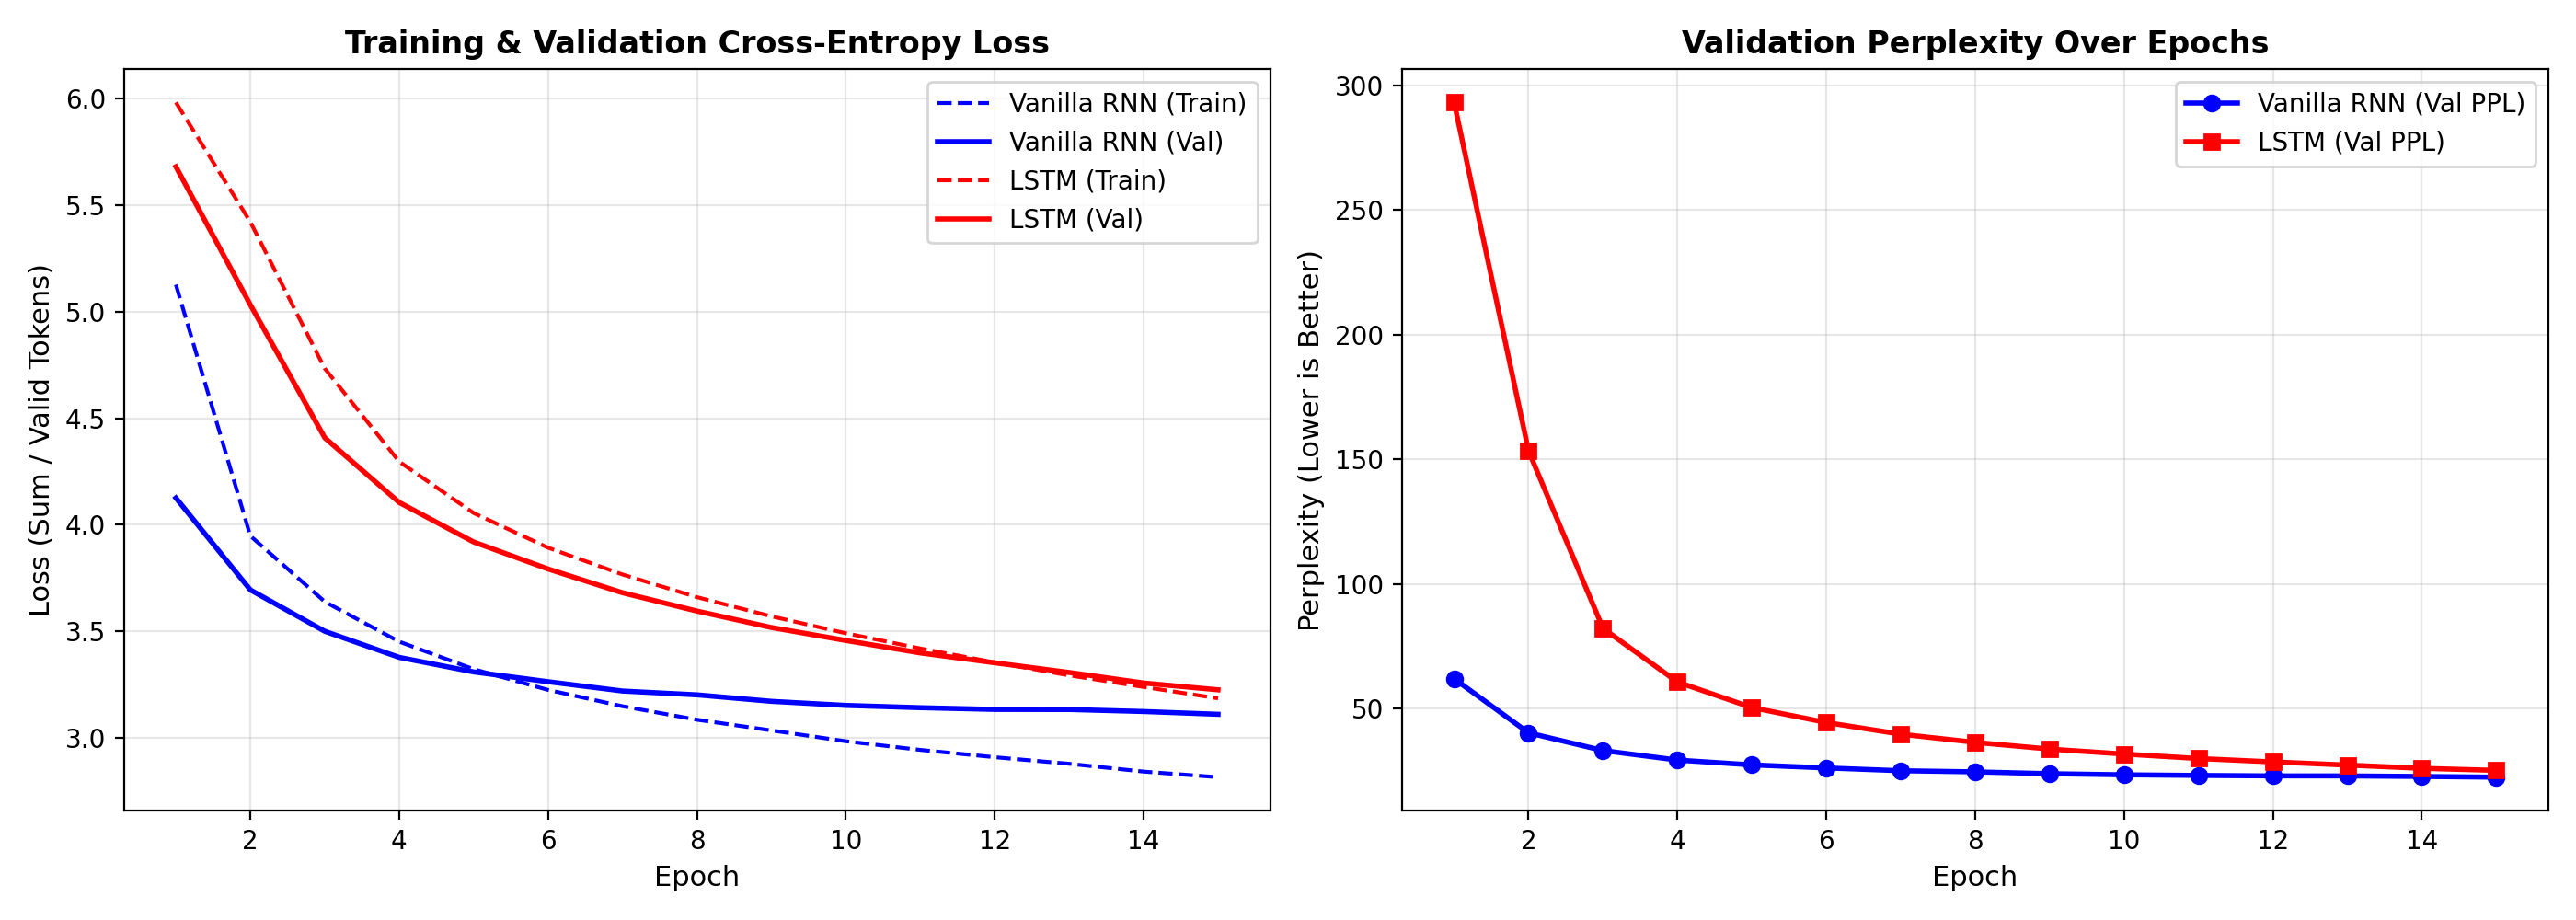

In [4]:
loss_plot_path = os.path.join(project_root, "outputs", "plots", "loss_curves.png")
if os.path.exists(loss_plot_path):
    display(Image(filename=loss_plot_path))
else:
    print("Loss plot not found at", loss_plot_path)